# QFire Cusco — Fase 03: recursos, solicitudes y distribución desde el COER

**Objetivo:** construir los datasets que necesitará el planificador para decidir qué recursos enviar, cuánto transportar y qué centros visitar. Toda ruta de los vehículos del escenario comienza en **COER_CUSCO**. Las solicitudes y centros locales se coordinan desde ese mismo origen.

Una entrega puede ser directa o pasar por un centro local, como la **OGRD de la Municipalidad Provincial de Paruro**, que podrá recibir transferencias, aportar donaciones recibidas allí y redistribuir a receptores. No se considera que cada localidad tenga otro COER: en este proyecto son centros locales propuestos. La etiqueta histórica **COES MININTER** identifica una entidad sectorial de reporte y no proporciona por sí sola la ubicación de un almacén.

Este notebook sigue la fase de fuente logística y demanda de Q-Med, adaptada a recursos para brigadas y con inventario por centro. **No programa despachos todavía:** entrega entradas, conectividad y restricciones a la fase 04.

Descargar y descomprimir el proyecto completo. Ejecutar desde la carpeta del proyecto o desde `notebooks/`, después de instalar `requirements.txt`. Las fases 01 y 02 están incluidas; sus salidas se conservan.

## 1. Qué proviene del historial y qué es un supuesto

| Dato | Procedencia y uso |
|---|---|
| ID, provincia, distrito, fecha y entidad reportante | Historial Cusco 2022–2026; se preservan |
| COER Cusco como origen/coordinador único | Regla del escenario solicitada por la usuaria |
| Personal, fauna, humo, trabajo manual y magnitud relativa | Perfiles **simulados**, editables en `config/perfiles_fase3.csv` |
| Pedidos, donaciones, flota, capacidades y plazos | **Simulados** para probar la logística |
| Carreteras y sentidos disponibles en OSM | Extracto vial real; tiempos estimados, sin tráfico ni bloqueos en vivo |
| Punto central y receptores | Ubicaciones operativas **provisionales**, sin validación de acceso |

Los cinco registros históricos sirven como referencias para cinco incidentes ficticios de un mismo escenario. **No se afirma que estén activos ni que hayan ocurrido simultáneamente.** La magnitud relativa de la demo no se obtiene de `COB_AFECTA`, cuya unidad sigue pendiente de confirmación. Menor fauna tampoco significa terreno desértico.

In [1]:
from pathlib import Path
import json
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.ticker import MaxNLocator
from IPython.display import display

def locate_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / 'config/phase3.json').is_file() and (candidate / 'src/qfire_cusco/logistics.py').is_file():
            return candidate
    raise FileNotFoundError('Descomprima qfire-cusco.zip completo y abra la carpeta del proyecto.')

ROOT = locate_project_root()
sys.path.insert(0, str(ROOT / 'src')) if str(ROOT / 'src') not in sys.path else None
from qfire_cusco.geospatial import read_history, prepare_network, snap_points, build_costs
from qfire_cusco.logistics import (
    read_config, load_inputs, demand_quantities, build_requests, build_donations,
    inventory_at, transfer_inventory, build_fleet, candidate_legs, resource_balance, export_phase3,
)
FIGURES = ROOT / 'outputs/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 70)
config = read_config(ROOT)
history = read_history(ROOT)
points, centers, catalog, profiles = load_inputs(ROOT, history, config)
print('Escenario:', config['escenario_id'])
print('Reloj ficticio:', config['reloj_escenario'], '| Horizonte:', config['horizonte_horas'], 'horas')
print('Historial preservado:', len(history), 'registros mapeables; no son incendios activos.')

Escenario: COER_CUSCO_DEMO_003
Reloj ficticio: 2026-10-24T08:00:00-05:00 | Horizonte: 12 horas
Historial preservado: 3363 registros mapeables; no son incendios activos.


## 2. Origen central y centros locales

`CENTRO_COORDINADOR_ID` siempre es `COER_CUSCO`. `CENTRO_PADRE_ID` permite conocer la dependencia de cada centro local. `CENTRO_PREFERENTE_ID` propone un abastecimiento local, pero no obliga a hacer una parada que resulte innecesaria: la fase 04 podrá comparar entrega directa y transferencia.

La ubicación del COER es un punto de demostración heredado de la fase 02, **no la sede oficial verificada**. Las referencias de Paruro, Accha y Huanoquite corresponden a centros de localidades de OSM, no a instalaciones confirmadas. Se guardan latitud/longitud originales y la fuente de cada coordenada para poder sustituirlas después.

In [2]:
display(centers[['CENTRO_ID', 'CENTRO_PADRE_ID', 'CENTRO_COORDINADOR_ID', 'ENTIDAD_REFERENCIA', 'ROL']])
display(points[['PUNTO_ID', 'TIPO', 'LATITUD', 'LONGITUD', 'FUENTE_COORDENADA', 'VALIDADO_OPERATIVAMENTE']])

,CENTRO_ID,CENTRO_PADRE_ID,CENTRO_COORDINADOR_ID,ENTIDAD_REFERENCIA,ROL
0,COER_CUSCO,,COER_CUSCO,COER DE CUSCO,CENTRAL
1,HUB_PARURO,COER_CUSCO,COER_CUSCO,OGRD DE LA MUNICIPALIDAD PROVINCIAL DE PARURO,HUB_LOCAL_PROPUESTO


,PUNTO_ID,TIPO,LATITUD,LONGITUD,FUENTE_COORDENADA,VALIDADO_OPERATIVAMENTE
0,COER_CUSCO,CENTRAL,-13.522600,-71.972300,PUNTO_DEMO_FASE2_NO_SEDE_VERIFICADA,False
1,HUB_PARURO,HUB,-13.761311,-71.847405,OSM_NODE_2314231210_CENTRO_LOCALIDAD_NO_ALMACEN,False
2,RE01,RECEPCION,-13.457000,-72.148000,PUNTO_DEMO_NO_PUNTO_SEGURO_VERIFICADO,False
3,RE02,RECEPCION,-13.304000,-72.116000,PUNTO_DEMO_NO_PUNTO_SEGURO_VERIFICADO,False
4,RE03,RECEPCION,-13.322000,-71.955000,PUNTO_DEMO_NO_PUNTO_SEGURO_VERIFICADO,False
5,RE04,RECEPCION,-13.971146,-71.831542,OSM_NODE_2314230985_CENTRO_LOCALIDAD_NO_RECEPCION_VALIDADA,False
6,RE05,RECEPCION,-13.681604,-72.017419,OSM_NODE_588509149_CENTRO_LOCALIDAD_NO_RECEPCION_VALIDADA,False


## 3. Catálogo y unidades de carga

Cada recurso conserva su presentación, peso y volumen. Agua, palas y paquetes no se suman como si fueran la misma unidad. El peso y el volumen se calculan por separado para revisar ambas capacidades de cada vehículo.

Los paquetes veterinarios y botiquines se tratan como **unidades cerradas solicitadas y autorizadas dentro de la simulación**. No se define su composición, medicamentos o dosis. Los pesos y volúmenes son supuestos logísticos y deben sustituirse por los de los bultos reales.

In [3]:
display(catalog)

,RECURSO_ID,NOMBRE,UNIDAD,PESO_KG_UNIDAD,VOLUMEN_M3_UNIDAD,REQUIERE_SOLICITUD_AUTORIZADA,FACTOR_PRIORIDAD,ORIGEN
0,AGUA,Agua embotellada 625 ml,BOTELLA,0.650,0.00080,False,1.0,SIMULADO
1,MASCARILLA,Mascarilla embolsada,UNIDAD,0.015,0.00015,False,0.8,SIMULADO
2,PALA,Pala,UNIDAD,2.000,0.01200,False,0.7,SIMULADO
3,HACHA,Hacha embalada,UNIDAD,1.800,0.00800,False,0.7,SIMULADO
4,PAQUETE_VETERINARIO,Paquete veterinario cerrado solicitado,PAQUETE,3.000,0.01400,True,1.0,SIMULADO
5,BOTIQUIN_BRIGADA,Botiquín cerrado solicitado,KIT,2.000,0.01000,True,1.0,SIMULADO


## 4. Necesidad por incendio y prioridad

La magnitud sigue influyendo, junto con el personal, la fauna y la urgencia reportada en el escenario. Estos atributos son entradas; no se predice la expansión del incendio.

La prioridad base usa la suma ponderada de atributos normalizados al máximo del escenario: **35% magnitud, 25% personal, 25% fauna y 15% urgencia**. Los pesos se editan en `config/phase3.json`. Esta puntuación es una política de demostración, no una clasificación oficial. Cambiar los incidentes también puede cambiar sus puntuaciones normalizadas.

La necesidad por recurso conserva su propia cantidad. Tener mayor prioridad general no genera una solicitud de palas que no se necesite. En la fase 04 se favorecerá la cobertura de pedidos pendientes y se mostrarán los faltantes; no basta con visitar primero al incidente más grande.

In [4]:
display(profiles[['PUNTO_ID', 'INCENDIO_ID', 'DISTRITO', 'PERSONAL_DESPLEGADO', 'FAUNA_REQUIERE_ATENCION',
                  'FRACCION_TRABAJO_MANUAL', 'MAGNITUD_RELATIVA', 'PRIORIDAD_BASE', 'CENTRO_PREFERENTE_ID', 'ENTIDAD_REPORTANTE']])
assert profiles.CENTRO_COORDINADOR_ID.eq('COER_CUSCO').all()
# Un valor histórico de ENTIDAD_REPORTANTE vacío se conserva vacío.
original_reporters = history.set_index('INCENDIO_ID').ENTIDAD_REPORTANTE
assert profiles.apply(lambda r: r.ENTIDAD_REPORTANTE == original_reporters[r.INCENDIO_ID], axis=1).all()

,PUNTO_ID,INCENDIO_ID,DISTRITO,PERSONAL_DESPLEGADO,FAUNA_REQUIERE_ATENCION,FRACCION_TRABAJO_MANUAL,MAGNITUD_RELATIVA,PRIORIDAD_BASE,CENTRO_PREFERENTE_ID,ENTIDAD_REPORTANTE
0,RE01,MINAM-109595,ANCAHUASI,90,1,0.80,100,75.8333,COER_CUSCO,
1,RE02,MINAM-109603,URUBAMBA,40,30,0.35,45,66.8611,COER_CUSCO,COER DE CUSCO
2,RE03,MINAM-109594,COYA,60,12,0.60,80,66.6667,COER_CUSCO,COER DE CUSCO
3,RE04,MINAM-109552,ACCHA,55,20,0.50,65,68.1944,HUB_PARURO,COER DE CUSCO
4,RE05,MINAM-108897,HUANOQUITE,25,2,0.75,25,26.3611,HUB_PARURO,


## 5. Construcción de solicitudes multirrecurso

Todos los coeficientes siguientes son **supuestos de la demo para el horizonte de 12 horas**, sin carácter de norma de consumo o atención. `ceil` redondea hacia arriba a unidades enteras. En un sistema real las solicitudes verificadas reemplazarían estas fórmulas.

| Recurso | Cantidad simulada por receptor |
|---|---|
| Agua, botella de 625 ml | `ceil(personal × 4)` |
| Mascarilla | `ceil(personal × 1,2 × factor_humo)` |
| Pala | `ceil(personal × fracción_trabajo_manual / 3)` |
| Hacha | `ceil(personal × fracción_trabajo_manual / 8)` |
| Paquete veterinario solicitado | `ceil(fauna_que_requiere_atención / 4)` |
| Botiquín de brigada solicitado | `ceil(personal / 25)` |

Cada línea incluye solicitud, incidente, receptor, recurso, cantidades solicitada/entregada/pendiente, prioridad, peso, volumen y plazo logístico simulado. Por ahora no hay entregas confirmadas.

In [5]:
requests = build_requests(profiles, catalog, config)
demand_table = requests.pivot(index='PUNTO_ID', columns='RECURSO_ID', values='CANTIDAD_PENDIENTE')
display(demand_table)
print('Líneas de solicitud:', len(requests))
display(requests[['SOLICITUD_ID', 'CENTRO_COORDINADOR_ID', 'RECURSO_ID', 'CANTIDAD_PENDIENTE',
                  'PESO_PENDIENTE_KG', 'VOLUMEN_PENDIENTE_M3', 'PRIORIDAD_RECURSO']].head(8))

RECURSO_ID,AGUA,BOTIQUIN_BRIGADA,HACHA,MASCARILLA,PALA,PAQUETE_VETERINARIO
PUNTO_ID,,,,,,
RE01,360,4,9,130,24,1
RE02,160,2,2,48,5,8
RE03,240,3,5,80,12,3
RE04,220,3,4,80,10,5
RE05,100,1,3,30,7,1


Líneas de solicitud: 30


,SOLICITUD_ID,CENTRO_COORDINADOR_ID,RECURSO_ID,CANTIDAD_PENDIENTE,PESO_PENDIENTE_KG,VOLUMEN_PENDIENTE_M3,PRIORIDAD_RECURSO
0,SOL-RE01-AGUA,COER_CUSCO,AGUA,360,234.00,0.2880,75.8333
1,SOL-RE01-MASCARILLA,COER_CUSCO,MASCARILLA,130,1.95,0.0195,60.6666
2,SOL-RE01-PALA,COER_CUSCO,PALA,24,48.00,0.2880,53.0833
3,SOL-RE01-HACHA,COER_CUSCO,HACHA,9,16.20,0.0720,53.0833
4,SOL-RE01-PAQUETE_VETERINARIO,COER_CUSCO,PAQUETE_VETERINARIO,1,3.00,0.0140,75.8333
5,SOL-RE01-BOTIQUIN_BRIGADA,COER_CUSCO,BOTIQUIN_BRIGADA,4,8.00,0.0400,75.8333
6,SOL-RE02-AGUA,COER_CUSCO,AGUA,160,104.00,0.1280,66.8611
7,SOL-RE02-MASCARILLA,COER_CUSCO,MASCARILLA,48,0.72,0.0072,53.4889


## 6. Comparar necesidades sin mezclar unidades

Cada columna del gráfico se normaliza por su propia cantidad máxima. Los números escritos conservan la cantidad original de ese recurso. Así se observa que Anta tiene más personal y agua, mientras Urubamba solicita más paquetes veterinarios aunque su magnitud relativa sea menor.

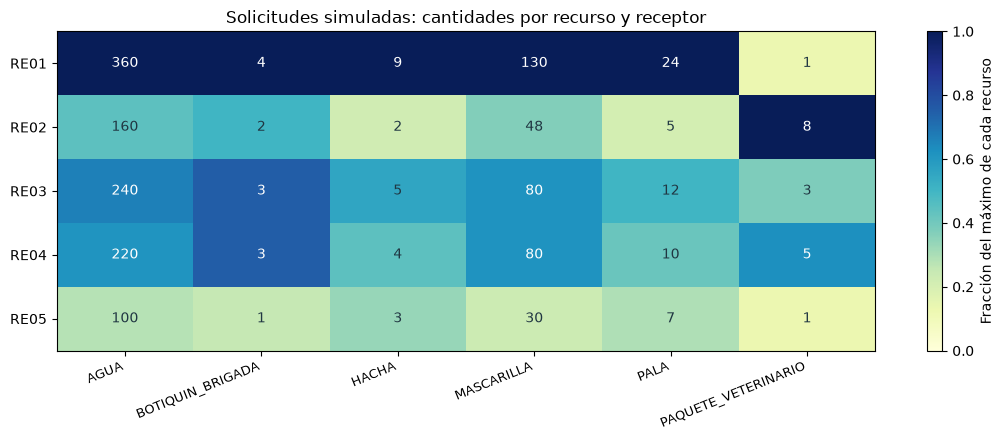

In [6]:
normalized = demand_table / demand_table.max().replace(0, 1)
fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(normalized, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(demand_table.columns)), demand_table.columns, rotation=22, ha='right', fontsize=9)
ax.set_yticks(range(len(demand_table)), demand_table.index)
for i in range(len(demand_table)):
    for j in range(len(demand_table.columns)):
        ax.text(j, i, str(int(demand_table.iloc[i, j])), ha='center', va='center',
                color='white' if normalized.iloc[i, j] > .6 else '#203642')
ax.set_title('Solicitudes simuladas: cantidades por recurso y receptor')
fig.colorbar(image, ax=ax, label='Fracción del máximo de cada recurso')
fig.tight_layout()
fig.savefig(FIGURES / '03_necesidades_por_recurso.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Donaciones y stock disponible en cada centro

Se crean donaciones recibidas y prometidas en ambos centros. También se incluyen casos futuros, en cuarentena y vencidos para comprobar su exclusión. Solo cuenta una donación recibida antes del reloj del escenario, liberada para entrega y con vigencia suficiente al momento de consulta. La fase 04 también tendrá que comprobar la vigencia al momento de la entrega.

Una donación recibida en Paruro **permanece en Paruro**. Para llevarla a otro centro se necesitará una recogida y un movimiento; no aparece automáticamente en el inventario del COER.

In [7]:
donations = build_donations(requests, centers, catalog, config)
inventory, ledger = inventory_at(donations, centers, catalog, config['reloj_escenario'])
display(donations.groupby(['CENTRO_ID', 'ESTADO']).size().rename('REGISTROS').reset_index())
display(inventory.pivot(index='CENTRO_ID', columns='RECURSO_ID', values='CANTIDAD_DISPONIBLE'))
print('Ingresos habilitados:', len(ledger), '| Donaciones registradas:', len(donations))
assert not ledger.DOCUMENTO_ORIGEN_ID.str.contains('PROMETIDA|FUTURA|CUARENTENA|VENCIDA').any()

,CENTRO_ID,ESTADO,REGISTROS
0,COER_CUSCO,PROMETIDA,6
1,COER_CUSCO,RECIBIDA,9
2,HUB_PARURO,PROMETIDA,6
3,HUB_PARURO,RECIBIDA,6


RECURSO_ID,AGUA,BOTIQUIN_BRIGADA,HACHA,MASCARILLA,PALA,PAQUETE_VETERINARIO
CENTRO_ID,,,,,,
COER_CUSCO,670,8,12,258,27,8
HUB_PARURO,112,2,3,39,6,3


Ingresos habilitados: 12 | Donaciones registradas: 27


## 8. Brechas por recurso

La cobertura agregada compara stock ubicado en los centros con demanda, recurso por recurso. **No es una asignación:** un stock situado en Paruro requiere transporte para abastecer otro lugar. Las restricciones de ruta, capacidad y tiempo pueden reducir la cobertura realizable.

Se crea escasez deliberada para que el próximo notebook tenga que priorizar, permitir entregas parciales y mostrar pedidos pendientes.

,RECURSO_ID,UNIDAD,DEMANDA_UNIDADES,STOCK_TOTAL_UBICADO,BRECHA_AGREGADA_UNIDADES,EXCEDENTE_AGREGADO_UNIDADES,COBERTURA_AGREGADA
0,AGUA,BOTELLA,1080,782,298,0,0.724074
1,MASCARILLA,UNIDAD,368,297,71,0,0.769231
2,PALA,UNIDAD,58,33,25,0,0.652174
3,HACHA,UNIDAD,23,15,8,0,0.807065
4,PAQUETE_VETERINARIO,PAQUETE,18,11,7,0,0.568966
5,BOTIQUIN_BRIGADA,KIT,13,10,3,0,0.611111


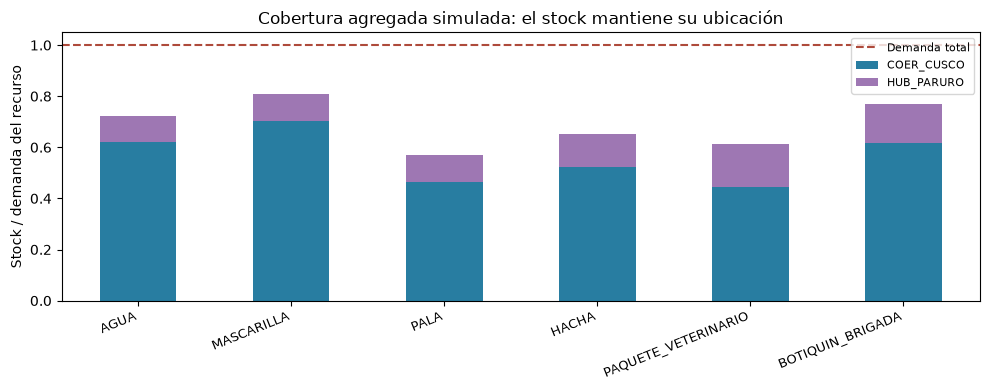

In [8]:
balance = resource_balance(requests, inventory, catalog)
display(balance.drop(columns='INTERPRETACION'))
fig, ax = plt.subplots(figsize=(10, 4))
center_stock = inventory.pivot(index='RECURSO_ID', columns='CENTRO_ID', values='CANTIDAD_DISPONIBLE')
denominator = balance.set_index('RECURSO_ID').DEMANDA_UNIDADES
fractions = center_stock.div(denominator, axis=0).reindex(catalog.RECURSO_ID)
fractions.plot.bar(stacked=True, color=['#287da1', '#9e77b3'], ax=ax)
ax.axhline(1, color='#ae4a3b', linestyle='--', label='Demanda total')
ax.set_ylabel('Stock / demanda del recurso')
ax.set_xlabel('')
ax.set_title('Cobertura agregada simulada: el stock mantiene su ubicación')
ax.set_xticklabels(ax.get_xticklabels(), rotation=22, ha='right', fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / '03_cobertura_por_centro.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Comprobación de una transferencia

Mover diez botellas del COER a Paruro debe restar diez en el origen y sumar diez en el destino. El total no cambia. Un movimiento repetido o sin stock libre se rechaza. Esta comprobación usa copias: **no se registra como un despacho real ni se modifica el escenario exportado**.

El optimizador futuro tendrá que reservar carga, registrar la carga a bordo y permitir redistribución solo después de la llegada de la transferencia correspondiente. No se podrá gastar dos veces el mismo inventario.

In [9]:
stock_test, ledger_test = transfer_inventory(inventory, ledger, 'PRUEBA-TR-001', 'COER_CUSCO', 'HUB_PARURO', 'AGUA', 10)
before = inventory.loc[inventory.RECURSO_ID.eq('AGUA'), ['CENTRO_ID', 'CANTIDAD_DISPONIBLE']].set_index('CENTRO_ID')
after = stock_test.loc[stock_test.RECURSO_ID.eq('AGUA'), ['CENTRO_ID', 'CANTIDAD_DISPONIBLE']].set_index('CENTRO_ID')
display(before.join(after, lsuffix='_ANTES', rsuffix='_DESPUES'))
pd.testing.assert_series_equal(inventory.groupby('RECURSO_ID').CANTIDAD_DISPONIBLE.sum(),
                              stock_test.groupby('RECURSO_ID').CANTIDAD_DISPONIBLE.sum())
try:
    transfer_inventory(stock_test, ledger_test, 'PRUEBA-TR-001', 'COER_CUSCO', 'HUB_PARURO', 'AGUA', 10)
    raise AssertionError('Se permitió un movimiento repetido')
except ValueError as error:
    print('Control esperado:', error)

/var/folders/2y/7nk_8xq918z2k4bbvnj_mw800000gn/T/ipykernel_90095/3350199439.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  display(before.join(after, lsuffix='_ANTES', rsuffix='_DESPUES'))


,CANTIDAD_DISPONIBLE_ANTES,CANTIDAD_DISPONIBLE_DESPUES
CENTRO_ID,,
COER_CUSCO,670,660
HUB_PARURO,112,122


Control esperado: ID de movimiento repetido.


## 10. Flota y conexiones logísticas candidatas

Los tres vehículos comienzan vacíos en COER Cusco. Una ruta futura podrá visitar un centro local para descargar transferencias, recoger donaciones o cargar recursos que ya estén disponibles allí.

Se preparan conexiones central–receptor, central–Paruro, Paruro–Accha/Huanoquite y una posible recogida Paruro–central. Son alternativas, no nueve viajes que deban ejecutarse. La fase 04 deberá construir secuencias completas con capacidad, disponibilidad, servicio en paradas y retornos al COER. Las capacidades de la flota son simuladas y no certifican acceso de esos vehículos a todas las vías.

In [10]:
fleet = build_fleet(config)
legs = candidate_legs(points, profiles, config)
display(fleet[['VEHICULO_ID', 'ORIGEN_RUTA_ID', 'CAPACIDAD_KG', 'CAPACIDAD_M3', 'DISPONIBLE_DESDE', 'DISPONIBLE_HASTA']])
display(legs)

,VEHICULO_ID,ORIGEN_RUTA_ID,CAPACIDAD_KG,CAPACIDAD_M3,DISPONIBLE_DESDE,DISPONIBLE_HASTA
0,VEH-01,COER_CUSCO,650,3.0,2026-10-24T08:00:00-05:00,2026-10-24T20:00:00-05:00
1,VEH-02,COER_CUSCO,900,4.5,2026-10-24T08:00:00-05:00,2026-10-24T20:00:00-05:00
2,VEH-03,COER_CUSCO,1200,6.0,2026-10-24T08:00:00-05:00,2026-10-24T20:00:00-05:00


,ORIGEN_ID,DESTINO_ID,USO,CENTRO_COORDINADOR_ID,ES_ASIGNACION
0,COER_CUSCO,RE01,ENTREGA_DIRECTA_CANDIDATA,COER_CUSCO,False
1,COER_CUSCO,RE02,ENTREGA_DIRECTA_CANDIDATA,COER_CUSCO,False
2,COER_CUSCO,RE03,ENTREGA_DIRECTA_CANDIDATA,COER_CUSCO,False
3,COER_CUSCO,RE04,ENTREGA_DIRECTA_CANDIDATA,COER_CUSCO,False
4,COER_CUSCO,RE05,ENTREGA_DIRECTA_CANDIDATA,COER_CUSCO,False
5,COER_CUSCO,HUB_PARURO,TRANSFERENCIA_CANDIDATA,COER_CUSCO,False
6,HUB_PARURO,COER_CUSCO,RECOGIDA_DONACIONES_CANDIDATA,COER_CUSCO,False
7,HUB_PARURO,RE04,REDISTRIBUCION_CANDIDATA,COER_CUSCO,False
8,HUB_PARURO,RE05,REDISTRIBUCION_CANDIDATA,COER_CUSCO,False


## 11. Ampliación vial para incluir Paruro

La red de fase 02 no alcanzaba el área de Accha y Paruro. Por eso esta fase incluye un **nuevo extracto OSM comprimido** y un grafo independiente en `data/geo/phase3/`. Las matrices anteriores permanecen disponibles como resultados de su propio escenario.

Se asocia cada ubicación propuesta a un nodo vial y se guarda la separación en metros. Estar cerca de la red no valida un almacén ni el acceso final. Si un punto supera 300 m, se detiene el cálculo para revisarlo. Las matrices dirigidas contienen km y minutos del mismo camino por menor tiempo estimado; un destino sin conexión mantiene infinito y `False`.

In [11]:
graph, network_manifest, network_mode = prepare_network(ROOT, points, config)
snapped_points = snap_points(graph, points, config['max_snap_m'])
costs = build_costs(graph, snapped_points)
distance_matrix, duration_matrix, reachability_matrix, road_pairs, routes = costs
print('Red:', network_mode, '| Versión:', network_manifest['red_version'])
print('Nodos:', graph.number_of_nodes(), '| Arcos dirigidos:', graph.number_of_edges())
display(snapped_points[['PUNTO_ID', 'DISTANCIA_A_NODO_M', 'SNAP_OK', 'ACCESO_ULTIMO_TRAMO_VALIDADO']].round(2))
display(duration_matrix.round(1))

Red: CACHE | Versión: 74c8c759471036bc8dc4
Nodos: 22508 | Arcos dirigidos: 58712


,PUNTO_ID,DISTANCIA_A_NODO_M,SNAP_OK,ACCESO_ULTIMO_TRAMO_VALIDADO
0,COER_CUSCO,33.95,True,False
1,HUB_PARURO,31.40,True,False
2,RE01,44.36,True,False
3,RE02,15.23,True,False
4,RE03,49.44,True,False
5,RE04,19.39,True,False
6,RE05,18.43,True,False


,COER_CUSCO,HUB_PARURO,RE01,RE02,RE03,RE04,RE05
PUNTO_ID,,,,,,,
COER_CUSCO,0.0,72.7,27.3,59.8,56.1,131.6,65.9
HUB_PARURO,72.6,0.0,96.4,128.8,125.9,59.1,63.6
RE01,27.4,96.4,0.0,36.0,54.6,155.3,84.2
RE02,59.9,128.9,36.1,0.0,22.9,187.8,120.3
RE03,56.1,126.8,54.6,22.8,0.0,185.7,121.9
RE04,131.5,59.1,155.3,187.8,184.9,0.0,122.6
RE05,65.8,63.6,84.2,120.2,121.9,122.6,0.0


## 12. Vista territorial y exportación

El gráfico sitúa central, centro local y receptores sobre carreteras OSM. No dibuja la expansión del fuego. El mapa HTML añade los caminos candidatos con sus geometrías viales; las teselas y bibliotecas JavaScript necesitan conexión a Internet.

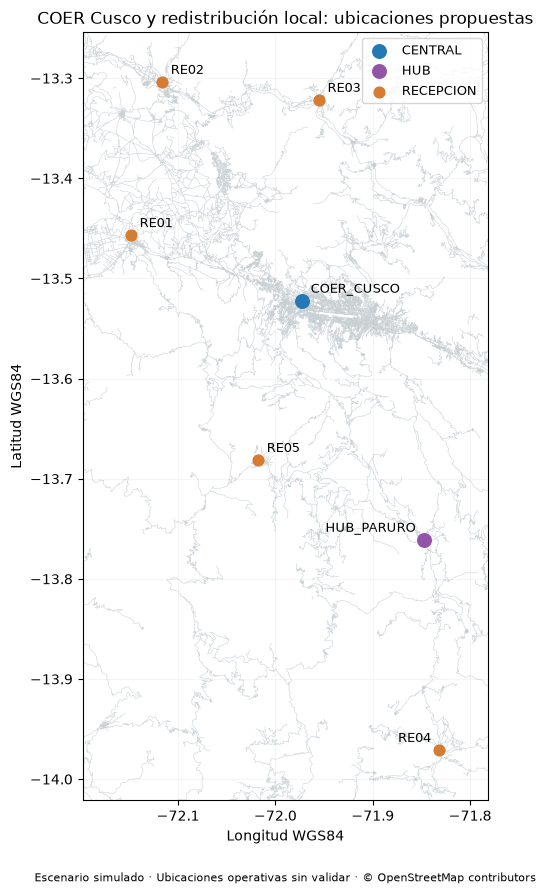

,ORIGEN_ID,DESTINO_ID,USO,ALCANZABLE,DISTANCIA_KM,DURACION_MIN
0,COER_CUSCO,RE01,ENTREGA_DIRECTA_CANDIDATA,True,26.27,27.34
1,COER_CUSCO,RE02,ENTREGA_DIRECTA_CANDIDATA,True,52.30,59.75
2,COER_CUSCO,RE03,ENTREGA_DIRECTA_CANDIDATA,True,50.91,56.13
3,COER_CUSCO,RE04,ENTREGA_DIRECTA_CANDIDATA,True,107.85,131.61
4,COER_CUSCO,RE05,ENTREGA_DIRECTA_CANDIDATA,True,42.26,65.91
5,COER_CUSCO,HUB_PARURO,TRANSFERENCIA_CANDIDATA,True,58.76,72.67
6,HUB_PARURO,COER_CUSCO,RECOGIDA_DONACIONES_CANDIDATA,True,58.84,72.57
7,HUB_PARURO,RE04,REDISTRIBUCION_CANDIDATA,True,49.26,59.14
8,HUB_PARURO,RE05,REDISTRIBUCION_CANDIDATA,True,46.74,63.62


Mapa guardado: outputs/maps/03_centros_y_recursos.html


In [12]:
fig, ax = plt.subplots(figsize=(8.5, 9))
segments = [list(d['geometry'].coords) for _, _, d in graph.edges(data=True)]
ax.add_collection(LineCollection(segments, colors='#c7cfd3', linewidths=.28, alpha=.7, zorder=1))
colors = {'CENTRAL': '#2478b4', 'HUB': '#9254a8', 'RECEPCION': '#d67c31'}
for role, group in snapped_points.groupby('TIPO'):
    ax.scatter(group.LONGITUD, group.LATITUD, s=95 if role != 'RECEPCION' else 60, color=colors[role], label=role, zorder=3)
    for p in group.itertuples():
        ax.annotate(p.PUNTO_ID, (p.LONGITUD, p.LATITUD), xytext=(-6 if p.LONGITUD > -71.9 else 6, 6), textcoords='offset points', ha='right' if p.LONGITUD > -71.9 else 'left', fontsize=9, zorder=4)
ax.set_xlim(snapped_points.LONGITUD.min()-.05, snapped_points.LONGITUD.max()+.05)
ax.set_ylim(snapped_points.LATITUD.min()-.05, snapped_points.LATITUD.max()+.05)
ax.set_aspect(1 / np.cos(np.deg2rad(snapped_points.LATITUD.median())))
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.set_xlabel('Longitud WGS84'); ax.set_ylabel('Latitud WGS84')
ax.set_title('COER Cusco y redistribución local: ubicaciones propuestas')
ax.legend(fontsize=9); ax.grid(alpha=.12)
fig.text(.5, .015, 'Escenario simulado · Ubicaciones operativas sin validar · © OpenStreetMap contributors', ha='center', fontsize=8)
fig.tight_layout(rect=[0,.04,1,1])
fig.savefig(FIGURES / '03_red_centros_y_receptores.png', dpi=150, bbox_inches='tight')
plt.show()
report, interactive_map, connected_legs = export_phase3(
    ROOT, config, snapped_points, centers, catalog, profiles, requests, donations,
    inventory, ledger, fleet, legs, network_manifest, costs,
)
display(connected_legs[['ORIGEN_ID', 'DESTINO_ID', 'USO', 'ALCANZABLE', 'DISTANCIA_KM', 'DURACION_MIN']].round(2))
print('Mapa guardado: outputs/maps/03_centros_y_recursos.html')

In [13]:
display(interactive_map)

## 13. Contratos de salida y controles

| Carpeta | Contenido |
|---|---|
| `config/` | Reglas, perfiles simulados, catálogo, centros y puntos editables de fase 03 |
| `data/simulated/phase3/` | Centros, catálogo, perfiles, solicitudes, donaciones, movimientos, inventario, flota, brechas y arcos candidatos |
| `data/optimization/phase3/` | Matrices de distancia, tiempo, conectividad y pares viales |
| `data/geo/phase3/` | Grafo, versión y geometrías de caminos |
| `outputs/maps/03_centros_y_recursos.html` | Mapa del escenario de distribución |
| `outputs/reports/phase3_summary.json` | Resumen, límites, hashes y conteos |

Las solicitudes se relacionan con el incendio y receptor mediante sus IDs; el inventario se relaciona con centro y recurso. Un mismo recurso transferido no se registra como otra donación. El escenario exporta solo los ingresos iniciales, sin la transferencia de prueba.

In [14]:
assert requests.SOLICITUD_ID.is_unique
assert requests.CENTRO_COORDINADOR_ID.eq(config['origen_central']).all()
assert requests.CANTIDAD_PENDIENTE.eq(requests.CANTIDAD_SOLICITADA - requests.CANTIDAD_ENTREGADA).all()
assert fleet.ORIGEN_RUTA_ID.eq(config['origen_central']).all()
assert inventory.CANTIDAD_DISPONIBLE.ge(0).all()
assert not ledger.MOVIMIENTO_ID.str.contains('PRUEBA').any()
assert snapped_points.SNAP_OK.all()
assert duration_matrix.index.tolist() == duration_matrix.columns.tolist() == snapped_points.PUNTO_ID.tolist()
assert connected_legs.RED_VERSION.eq(network_manifest['red_version']).all()
for resource in catalog.RECURSO_ID:
    assert inventory.loc[inventory.RECURSO_ID.eq(resource), 'CANTIDAD_DISPONIBLE'].sum() == ledger.loc[ledger.RECURSO_ID.eq(resource), 'CANTIDAD'].sum()
print('Controles completados: origen COER, trazabilidad, stock, solicitudes, unidades y matrices.')
print('Receptores:', report['receptores'], '| Recursos:', report['recursos'], '| Líneas:', report['lineas_solicitud'])
print('Trayectos candidatos sin conexión:', report['arcos_candidatos_inalcanzables'])
print('Operaciones despachadas:', report['operaciones_despachadas'])

Controles completados: origen COER, trazabilidad, stock, solicitudes, unidades y matrices.
Receptores: 5 | Recursos: 6 | Líneas: 30
Trayectos candidatos sin conexión: 0
Operaciones despachadas: 0


## Resultado y siguiente fase

Esta fase deja la demanda diferenciada por recurso, el inventario ubicado por centro y una flota que parte del COER Cusco. Permite preparar entregas directas o mediante Paruro, con aportes locales que mantienen su trazabilidad.

La **fase 04** tendrá que asignar cantidades con stock escaso y construir rutas. Deberá conservar peso, volumen y carga a bordo en cada parada; registrar recogidas y descargas; respetar llegada de transferencias antes de su redistribución; evitar doble reserva; permitir entregas parciales y reportar pedidos inaccesibles. Se compararán fracciones de pedido satisfechas por recurso, no la suma de botellas y herramientas.

La **fase 05** comparará una subinstancia pequeña con QUBO/QAOA y una referencia clásica usando iguales costos y restricciones. La **fase 06** aplicará bloqueos al grafo y recalculará desde la posición y carga vigentes; no reiniciará todos los vehículos en el COER si ya están en camino.

**Fuentes:** historial proporcionado con procedencia [MINAM](https://geoservidorperu.minam.gob.pe/arcgis/rest/services/CFOI_Dashboard_mensuales_pruebas/MapServer/0), [OpenStreetMap](https://www.openstreetmap.org/copyright), [Geofabrik Perú](https://download.geofabrik.de/south-america/peru.html). Para la distinción entre COER, COEL y COES se consultó [INDECI](https://portal.indeci.gob.pe/coen/centros-de-operacion-de-emergencia/). Los centros de este escenario no se presentan como una red de almacenes oficialmente acreditada.